In [1]:
import re
import random
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.7.1+cu128
Device: cuda
GPU: NVIDIA GeForce GTX 1650


In [2]:
sentences = [
    # Royalty and relationships
    "king queen prince princess royal kingdom palace",
    "the king rules the kingdom from his royal palace",
    "the queen is the wife of the king",
    "the prince is the son of the king and queen",
    "the princess is the daughter of the king and queen",
    "the king and queen live in the palace",
    "the prince and princess belong to the royal family",

    # Gender and people
    "man woman boy girl person people",
    "the man is strong and the woman is strong",
    "the boy is young and the girl is young",
    "the man is the father of the boy",
    "the woman is the mother of the girl",
    "a boy grows into a man",
    "a girl grows into a woman",

    # Countries, cities and languages
    "paris is the capital of france",
    "berlin is the capital of germany",
    "rome is the capital of italy",
    "france paris french europe",
    "germany berlin german europe",
    "italy rome italian europe",
    "people in france speak french",
    "people in germany speak german",
    "people in italy speak italian",
    "paris berlin and rome are european cities",

    # Animals and pets
    "cat dog animal pet puppy kitten",
    "a cat is a small domestic animal",
    "a kitten is a young cat",
    "a puppy is a young dog",
    "dogs and cats are popular pets",
    "a dog is a loyal animal",
    "a cat can be a friendly pet",
    "puppies and kittens are young animals",

    # Machine learning and artificial intelligence
    "machine learning is a branch of artificial intelligence",
    "artificial intelligence allows machines to perform intelligent tasks",
    "deep learning is a branch of machine learning",
    "neural networks are used in deep learning",
    "a neural network contains interconnected neurons",
    "machine learning models learn patterns from data",
    "deep learning models learn complex patterns",
    "training data is used to train machine learning models",
    "artificial neural networks are inspired by the human brain",
    "data science uses statistics and machine learning",
    "a trained model makes predictions on new data",
    "natural language processing helps computers understand text",
    "computer vision helps machines understand images",
    "deep learning is used in computer vision and natural language processing",
] * 100

def tokenize(text):
    return re.findall(r"\b[a-z]+\b", text.lower())

tokenized_sentences = [tokenize(s) for s in sentences]

vocab = sorted(set(word for sent in tokenized_sentences for word in sent))
word_to_idx = {word: i for i, word in enumerate(vocab)}
idx_to_word = {i: word for word, i in word_to_idx.items()}

vocab_size = len(vocab)

print("Vocabulary size:", vocab_size)
print("Sample vocabulary:", vocab[:20])

Vocabulary size: 117
Sample vocabulary: ['a', 'allows', 'and', 'animal', 'animals', 'are', 'artificial', 'be', 'belong', 'berlin', 'boy', 'brain', 'branch', 'by', 'can', 'capital', 'cat', 'cats', 'cities', 'complex']


In [3]:
# Generate Skip-gram pairs

WINDOW_SIZE = 2  
pairs = []

for sentence in tokenized_sentences:
    ids = [word_to_idx[word] for word in sentence]

    for centre_pos,target_id in enumerate(ids):
        start = max(0,centre_pos - WINDOW_SIZE)
        end = min(len(ids), centre_pos + WINDOW_SIZE + 1)

        for context_pos in range(start,end):
            if context_pos != centre_pos:
                pairs.append((target_id,ids[context_pos]))

targets  = torch.tensor([p[0] for p in pairs], dtype = torch.long)
contexts = torch.tensor([p[1] for p in pairs], dtype = torch.long)

dataset = TensorDataset(targets, contexts)

loader = DataLoader(
    dataset,
    batch_size= 512,
    shuffle= True,
    pin_memory=(device.type == 'cuda')
)

print("Training Pairs: ",len(dataset))
print("Example:", idx_to_word[targets[0].item()],
      "→", idx_to_word[contexts[0].item()])       

Training Pairs:  101200
Example: king → queen


In [4]:
# Implement Skip-gram with Negative Sampling

class SkipGramNS(nn.Module):
    def __init__(self,vocab_size,embedding_dim):
        super(). __init__()

        # establsing the input and output embedding 
        # suppose vocab size is 50 we can choose our own embedding dim 50,100...
        # input_embeddings: Learns a vector for each word when it acts as the target word.
        # output_embeddings: Learns a vector for each word when it acts as a context word.
        # suppose 50,100 means we have 5000 trainable value in matrix 
        self.input_embeddings = nn.Embedding(vocab_size,embedding_dim)
        self.output_embeddings = nn.Embedding(vocab_size,embedding_dim)

        # assinging random values for target word in range of (-0.5/embedding_dim , 0.5/embedding_dim)
        # assinging zeros for context vector 
        nn.init.uniform_(self.input_embeddings.weight, -0.5/embedding_dim , 0.5/embedding_dim)
        nn.init.zeros_(self.output_embeddings.weight)


    def forward(self,target,context,negatives):

            target_vec = self.input_embeddings(target)
            context_vec = self.output_embeddings(context)
            negative_vec = self.output_embeddings(negatives)
            
            # postive_score is only multiply with corresponding elements 
            # negative_score is multplied with multiple words NUM_NEGATIVES
            # so we chaning the dimension fo the target_vec using unsqeeze(2) adding 3rd dimesion (0,1,2)
            # finally squeeze(2) to get 2 dimensional 
            postive_score = (target_vec * context_vec).sum(dim = 1) 
            negative_score = torch.bmm(
                negative_vec ,target_vec.unsqueeze(2) 
            ).squeeze(2)
      
            # we applying - becuase 
            # if negative_Score is -3 * -1 we get +3 --> lower loss 
            # if negative_Score is +3 * -1 we get -3 --> higher loss
            positive_loss = F.logsigmoid(postive_score)
            negative_loss = F.logsigmoid(-negative_score).sum(dim = 1)
            
            # we reversing the direction coz our objective is minimize the loss 
            # logsigmoid gives negative values 
            # suppose -5 minimize -7  -9 ..
            # but our objective is move to zero 
            # so we flippin it 
            return -(positive_loss + negative_loss).mean()

EMBEDDING_DIM = 50
NUM_NEGATIVES = 5

model = SkipGramNS(vocab_size, EMBEDDING_DIM).to(device)

# Negative sampling distribution: frequency ** 0.75
# We use the \(0.75\) power to create a more balanced negative-sampling distribution, 
# helping Word2Vec learn richer word relationships

# Word	       Original probability	After power 0.75
# Cat (100)	   90.1%	 82.7%
# Dog (10)	   9.0%	     14.7%
# Airplane (1) 0.9%	     2.6%

# now model can use everything better instead of relying on cat alone 

word_counts = Counter(
    word for sentence in tokenized_sentences for word in sentence
)
counts = torch.tensor(
    [word_counts[idx_to_word[i]] for i in range(vocab_size)],
    dtype=torch.float
)
noise_distribution = counts.pow(0.75)
noise_distribution /= noise_distribution.sum()
noise_distribution = noise_distribution.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.003)

print(model)
print("Parameters:", sum(p.numel() for p in model.parameters()))         

SkipGramNS(
  (input_embeddings): Embedding(117, 50)
  (output_embeddings): Embedding(117, 50)
)
Parameters: 11700


In [5]:
# Traing the model 

EPOCHS = 10

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0

    for target, context in loader:
        target = target.to(device, non_blocking=True)
        context = context.to(device, non_blocking=True)

        batch_size = target.size(0)

        negatives = torch.multinomial(
            noise_distribution, # it have probability for each word id
            batch_size * NUM_NEGATIVES, # how many words we required -->for each word how many negative sample 
            replacement=True
        ).view(batch_size, NUM_NEGATIVES)# now view would (512,5) accroding to our example 

        # Avoid accidentally sampling the actual positive context.
        mask = negatives.eq(context.unsqueeze(1)) # covert the context to 2d and broadcasting then using eq comparsion is done
        # if anything matches True
        while mask.any():
            negatives[mask] = torch.multinomial(
                noise_distribution, int(mask.sum()), replacement=True
            ) # it will be replaced using this function 
            mask = negatives.eq(context.unsqueeze(1))

        optimizer.zero_grad(set_to_none=True)
        loss = model(target, context, negatives)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * batch_size

    avg_loss = total_loss / len(dataset)
    print(f"Epoch {epoch + 1:02d}/{EPOCHS} | Loss: {avg_loss:.4f}")

Epoch 01/10 | Loss: 2.8772
Epoch 02/10 | Loss: 1.8016
Epoch 03/10 | Loss: 1.2440
Epoch 04/10 | Loss: 1.1277
Epoch 05/10 | Loss: 1.0933
Epoch 06/10 | Loss: 1.0735
Epoch 07/10 | Loss: 1.0675
Epoch 08/10 | Loss: 1.0605
Epoch 09/10 | Loss: 1.0605
Epoch 10/10 | Loss: 1.0591


In [6]:
# Extract embeddings and cosine similarity

model.eval()

with torch.no_grad():
    # Extracts an independent copy of the trained input embedding weights, moves it to the CPU, and disables gradient tracking for analysis
    embeddings = model.input_embeddings.weight.detach().cpu().clone()

# Normalize so cosine similarity is a dot product.
# for [3,4] it would be v = sqrt(3^2 + 4^2) = 5 
# 3/5,4/5 --> 0.6 ,0.8
normalized_embeddings = F.normalize(embeddings, p=2, dim=1)

def cosine_similarity_words(word1, word2):
    i, j = word_to_idx[word1], word_to_idx[word2]
    return torch.dot(
        normalized_embeddings[i], normalized_embeddings[j]
    ).item() # dot product multiplication 

print("king ↔ queen:", cosine_similarity_words("king", "queen"))
print("cat  ↔ dog:  ", cosine_similarity_words("cat", "dog"))
print("cat  ↔ berlin:", cosine_similarity_words("cat", "berlin"))

king ↔ queen: 0.5673168897628784
cat  ↔ dog:   0.7672455310821533
cat  ↔ berlin: 0.3338576555252075


In [7]:
def nearest_neighbors(word, top_k=5):
    if word not in word_to_idx:
        raise ValueError(f"'{word}' is not in the vocabulary.")

    word_id = word_to_idx[word]
    query_vector = normalized_embeddings[word_id]

    scores = normalized_embeddings @ query_vector # matrix dot multplication to get score for each word in each row
    scores[word_id] = -float("inf") # normally for same word we would get score 1 to avoid minimize for that word id we reduce it -inf

    values, indices = torch.topk(
        scores, k=min(top_k, vocab_size - 1)
    ) # gives top_k values in our eg its 5 

    return [
        (idx_to_word[i.item()], round(score.item(), 4))
        for score, i in zip(values, indices)
    ]


for word in ["king", "cat", "paris", "learning"]:
    print(f"\nNearest neighbors of '{word}':")
    for neighbor, score in nearest_neighbors(word):
        print(f"  {neighbor:<15} {score:.4f}")


Nearest neighbors of 'king':
  live            0.7973
  father          0.7466
  daughter        0.7429
  wife            0.7387
  son             0.7352

Nearest neighbors of 'cat':
  loyal           0.7886
  dog             0.7672
  can             0.7162
  pet             0.7075
  be              0.7065

Nearest neighbors of 'paris':
  rome            0.7550
  french          0.6091
  speak           0.6061
  europe          0.6005
  capital         0.5889

Nearest neighbors of 'learning':
  branch          0.7351
  complex         0.6797
  statistics      0.5666
  patterns        0.5652
  models          0.5647


In [17]:
def analogy(word_a, word_b, word_c, top_k=5):
    # A - B + C
    # king - man ≈ queen - woman
    # Therefore, king - man + woman ≈ queen
    # we gonna check whether the highest score would be queen 
    query = (
        embeddings[word_to_idx[word_a]]
        - embeddings[word_to_idx[word_b]]
        + embeddings[word_to_idx[word_c]]
    )

    query = F.normalize(query.unsqueeze(0), p=2, dim=1).squeeze(0)
    scores = normalized_embeddings @ query

    # Exclude input words from the results
    for word in [word_a, word_b, word_c]:
        scores[word_to_idx[word]] = -float("inf")

    values, indices = torch.topk(scores, min(top_k, vocab_size - 3))

    return [
        (idx_to_word[i.item()], round(score.item(), 4))
        for score, i in zip(values, indices)
    ]


print("king - man + woman:")
for word, score in analogy("king", "man", "woman"):
    print(f"{word:<15} {score:.4f}")

king - man + woman:
live            0.7288
princess        0.6194
belong          0.6042
father          0.5752
daughter        0.5713


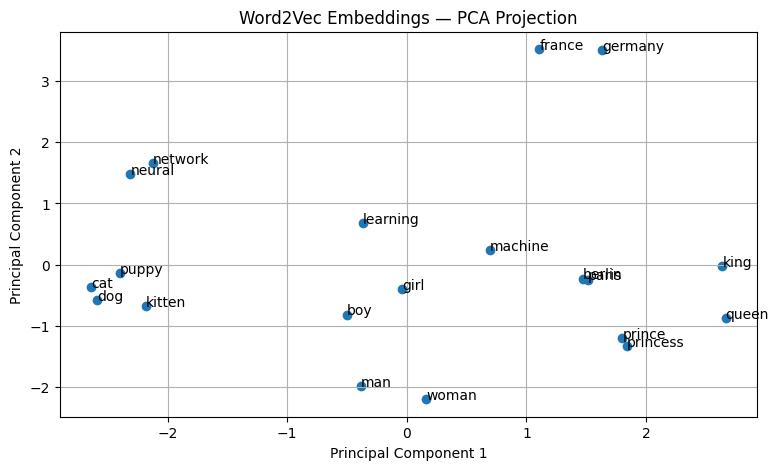

In [9]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

words_to_plot = [
    "king", "queen", "prince", "princess",
    "man", "woman", "boy", "girl",
    "paris", "france", "berlin", "germany",
    "cat", "dog", "puppy", "kitten",
    "machine", "learning", "neural", "network"
]

vectors = torch.stack([
    embeddings[word_to_idx[word]] for word in words_to_plot
]).numpy()

points_2d = PCA(n_components=2).fit_transform(vectors)

plt.figure(figsize=(9, 5))
plt.scatter(points_2d[:, 0], points_2d[:, 1])

for i, word in enumerate(words_to_plot):
    plt.annotate(word, (points_2d[i, 0], points_2d[i, 1]))

plt.title("Word2Vec Embeddings — PCA Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.show()

In [10]:
test_words = [
    "king",
    "queen",
    "cat",
    "dog",
    "paris",
    "france",
    "learning",
    "neural",
]

for word in test_words:
    print(f"\nNearest neighbors of '{word}':")
    for neighbor, similarity in nearest_neighbors(word, top_k=5):
        print(f"  {neighbor:<15} {similarity:.4f}")


Nearest neighbors of 'king':
  live            0.7973
  father          0.7466
  daughter        0.7429
  wife            0.7387
  son             0.7352

Nearest neighbors of 'queen':
  prince          0.7592
  rules           0.6801
  live            0.6639
  belong          0.6604
  princess        0.5942

Nearest neighbors of 'cat':
  loyal           0.7886
  dog             0.7672
  can             0.7162
  pet             0.7075
  be              0.7065

Nearest neighbors of 'dog':
  loyal           0.7678
  cat             0.7672
  puppy           0.7306
  friendly        0.7196
  kitten          0.7108

Nearest neighbors of 'paris':
  rome            0.7550
  french          0.6091
  speak           0.6061
  europe          0.6005
  capital         0.5889

Nearest neighbors of 'france':
  italy           0.7578
  germany         0.7536
  europe          0.6590
  french          0.6277
  speak           0.5780

Nearest neighbors of 'learning':
  branch          0.7351
  complex